# Bokeh 的基本用法

Bokeh 是用来在浏览器里显示图的库：绘制由浏览器的 JavaScript 来做，Python 只负责做出图的数据结构、更新数据。

与 matplotlib 相比，Bokeh 的长处是交互操作，加提示框、缩放、平移都很容易；它能存成 HTML 文件，也能嵌进 Flask 或 Django 的应用里。matplotlib 以静态图为主，交互功能比较弱。

这一章按下面的顺序说明。

- 显示图的方式(Notebook、HTML、服务器)
- 用 JavaScript 与 Python 更新图
- Bokeh 的模型与属性
- 查找模型
- 回调、部件、布局

In [1]:
import numpy as np
import helper.magics
import bokeh

## 显示图的方式

Bokeh 有 4 种用法。

1. 在 Notebook 里做图，显示在格子的输出里。
2. 写成 HTML 文件，图的信息以 JSON 的形式放进 HTML，在没有 Python 的 PC 上也能用浏览器看，还能平移与缩放。
3. 在 Notebook 里显示之后，用 Python 改数据送到浏览器，更新图。
4. 用 Bokeh 服务器把 Python 的脚本公开到网络上，网络里任何地方都能用 URL 打开；有按钮、输入框、选择框这些部件，也能做多人同时使用的应用。

这一节用简单的例子介绍这 4 种用法。

### 显示在 Notebook 里

要在 Notebook 里显示 Bokeh 的图，先执行 `output_notebook()`，这样就会从网络读入 Bokeh 的 JavaScript；连不上网时，请看这一章最后的一节。

In [2]:
import bokeh
from bokeh.plotting import output_notebook, figure, show, save

output_notebook()

Loading BokehJS ...

下面的程序画两条曲线：❶ 用 `figure()` 做出 `Figure` 的 `fig`，❷ 用 `line()` 做出曲线的对象，两个位置参数是各点的 x 与 y。❸ 用 `fig.legend[0]` 取到图例，用 `update()` 决定属性，❹ 用 `show()` 显示。

属性也可以在创建时用关键字参数指定，例如 `x_range`、`color`、`line_width`；用 `update()` 则能一次指定 `location`、`orientation` 这类属性。

In [3]:
def plot_demo():
    x = np.linspace(-2, 2, 400)
    fig = figure(width=500, height=300, title="正弦余弦曲線", x_range=(0, 1))  # ❶
    line_sin = fig.line(
        x,
        np.sin(2 * np.pi * x),
        color="red",
        legend_label="sin",
        line_width=2,
        name="sin",
    )  # ❷
    line_cos = fig.line(
        x,
        np.cos(2 * np.pi * x),
        color="green",
        legend_label="cos",
        line_width=2,
        name="cos",
    )
    fig.legend[0].update(location="bottom_left", orientation="horizontal")  # ❸
    return fig, (line_sin, line_cos)


fig, _ = plot_demo()
show(fig)  # ❹

用 `save()` 能把图存成 HTML 文件。上面那段代码调多次的话，浏览器里新的图会盖掉旧的，但 Python 里会做出好几个 `Figure`，它们都进当前的 `Document`；`save()` 会把那个 `Document` 里的图全部写进 HTML。

❶ 当前的 `Document` 可以用 `curdoc()` 取到，用 `clear()` 清掉内容。❷ 给 `save()` 传 `resources=CDN`，就会从网络的 CDN 读 Bokeh 的 JavaScript 与 CSS：HTML 变小，但看的时候需要联网。

In [4]:
from bokeh.resources import CDN
from bokeh.plotting import curdoc

curdoc().clear()  # ❶
save(fig, "sincos.html", resources=CDN, title="Plots");  # ❷

### 用 JavaScript 更新图

Bokeh 备齐了做界面的部件，能用 JavaScript 响应事件。下面的例子里拖动滑块，两条曲线的频率就会变；更新由 JavaScript 做，因此没有 Python 也能动。

In [5]:
from bokeh.models import Slider, CustomJS, GraphRenderer
from bokeh.layouts import column

fig, (line_sin, line_cos) = plot_demo()
freq_slider = Slider(title="freq", start=1, end=10, step=0.1, value=1)
layout = column(freq_slider, fig)

js_code = """
let freq = cb_obj.value;
let data_sin = line_sin.data_source.data;
let data_cos = line_cos.data_source.data;

data_sin.y = data_sin.x.map(x => Math.sin(2*Math.PI*freq*x));
data_cos.y = data_cos.x.map(x => Math.cos(2*Math.PI*freq*x));

line_sin.data_source.change.emit();
line_cos.data_source.change.emit();
"""

update_plot = CustomJS(args=dict(line_sin=line_sin, line_cos=line_cos), code=js_code)
freq_slider.js_on_change("value", update_plot)
show(layout)

事件的处理在浏览器的 JavaScript 里跑，写成 HTML 之后滑块照样管用，下面的程序把 `layout` 存成 HTML，再用浏览器打开，请拖动滑块确认曲线会变。

In [6]:
import os
import webbrowser

curdoc().clear()
html_fn = save(layout, "sincos_freq.html", resources=CDN, title="Plots")
if os.environ.get("SCIPYBOOK_OPEN_BROWSER"):  # 只在本地查看时打开
    webbrowser.open_new_tab(html_fn)
print(html_fn)

C:\Users\ruoyu\Documents\notebooks\scipybook\scipybook_cn\sincos_freq.html


### 用 Python 更新图

到这里为止的办法都是一次性的：Python 把做好的结构变成 JSON 送到浏览器显示，显示之后就无法再从 Python 改图。

下面的例子里 ❶ 用滑块的 `on_change()` 登记 `value` 变化时调用的函数。❷ 这个函数会收到属性名、原来的值与新值 3 个参数，函数里取到 `data_source`，改写 `data` 的 y。

用 `show(layout)` 能显示出滑块与图，但拖动也不会变，因为 Python 的函数只在 Bokeh 服务器里才起作用。

要在 Notebook 里试函数，得用 `jupyter_bokeh`。

In [7]:
import jupyter_bokeh as jbk

from bokeh.models import Slider
from bokeh.layouts import column

fig, (line_sin, line_cos) = plot_demo()
freq_slider = Slider(title="freq", start=1, end=10, step=0.1, value=1)
layout = column(freq_slider, fig)


def update_plot(name, old, new):  # ❷
    x = line_sin.data_source.data["x"]
    line_sin.data_source.data.update(y=np.sin(2 * np.pi * new * x))
    x = line_cos.data_source.data["x"]
    line_cos.data_source.data.update(y=np.cos(2 * np.pi * new * x))


freq_slider.on_change("value", update_plot)  # ❶
jbk.BokehModel(layout)  # ❸

BokehModel(render_bundle={'docs_json': {'fec6b691-e85e-41c6-b206-cfc8398dec0f': {'version': '3.9.2', 'title': …

### Bokeh 服务器

用 Bokeh 的服务器功能，能给多个使用者各自显示不同的画面：服务器把使用者的脚本放在另一个进程里跑，在脚本所在的文件夹执行下面的命令，服务器就起来了，并用浏览器打开。

```
bokeh serve bokeh_serve_demo.py -show
```

接着用 Notebook 的 `%%writefile` 把代码写进 `bokeh_serve_demo.py`。

In [8]:
%%writefile bokeh_serve_demo.py
import numpy as np
from bokeh.io import curdoc
from bokeh.plotting import figure
from bokeh.models import Slider
from bokeh.layouts import column

def plot_demo():
    x = np.linspace(0, 1, 200)    
    fig = figure(width=500, height=300, title="正弦余弦曲線", x_range=(0, 1))
    line_sin = fig.line(x, np.sin(2*np.pi*x), color="red", legend_label="sin", line_width=2, name="sin")
    line_cos = fig.line(x, np.cos(2*np.pi*x), color="green", legend_label="cos", line_width=2, name="cos")
    fig.legend[0].update(location="bottom_center", orientation="horizontal")
    return fig, (line_sin, line_cos)

def serve_demo(doc):
    fig, (line_sin, line_cos) = plot_demo()
    freq_slider = Slider(title="freq", start=1, end=10, step=0.1, value=1)

    def freq_changed(attr, old, new):
        freq = new
        x = line_sin.data_source.data["x"]
        y = np.sin(2*np.pi*freq*x)
        line_sin.data_source.data = dict(x=x, y=y)

        x = line_cos.data_source.data["x"]
        y = np.cos(2*np.pi*freq*x)
        line_cos.data_source.patch({"y":[np.s_[:, y]]})
        
    freq_slider.on_change("value", freq_changed)

    layout = column(freq_slider, fig)
    doc.add_root(layout)
    
serve_demo(curdoc())

Writing bokeh_serve_demo.py


如图所示，每次在浏览器里开新窗口访问地址，整个程序都会在新的环境里运行一次，做出新的 `Document`：Python 的 `Document` 送到浏览器，JavaScript 那边也做出同样结构的 `Document`。每个使用者的滑块位置因此各自不同，看到的是不同频率的波形。

![](images/bokeh_server.svg)

### 把服务器嵌进 Notebook

给 `show()` 传一个函数，内核的进程里就会起 Bokeh 服务器，并把新的 `Document` 交给那个函数。这个办法只能用 Bokeh 的部件，不能用 ipywidgets；Notebook 的地址不是默认的 `'localhost:8888'` 时，要把那个地址传给 `notebook_url`。

可以先用这个办法在 Notebook 里试，跑通了再写进文件、当作单独的服务器来跑。

In [9]:
def serve_demo(doc):
    fig, (line_sin, line_cos) = plot_demo()
    freq_slider = Slider(title="freq", start=1, end=10, step=0.1, value=1)

    def freq_changed(attr, old, new):
        freq = new
        x = line_sin.data_source.data["x"]
        y = np.sin(2 * np.pi * freq * x)
        line_sin.data_source.data = dict(x=x, y=y)

        x = line_cos.data_source.data["x"]
        y = np.cos(2 * np.pi * freq * x)
        line_cos.data_source.patch({"y": [np.s_[:, y]]})

    freq_slider.on_change("value", freq_changed)

    layout = column(freq_slider, fig)
    doc.add_root(layout)


show(serve_demo)

## Bokeh 的模型

Bokeh 的类都从 `Model` 派生，而 `Model` 从 `HasProps` 派生；继承 `HasProps` 的类可以定义 Bokeh 属性，属性里带着类型、值的检查、默认值与说明。

下面的程序显示图对象 `figure` 的派生关系。

In [10]:
from bokeh.plotting import figure

figure.mro()

[bokeh.plotting._figure.figure,
 bokeh.models.plots.Plot,
 bokeh.models.layouts.LayoutDOM,
 bokeh.models.ui.panes.Pane,
 bokeh.models.ui.ui_element.UIElement,
 bokeh.models.ui.ui_element.StyledElement,
 bokeh.model.model.Model,
 bokeh.core.has_props.HasProps,
 bokeh.core.serialization.Serializable,
 bokeh.model.util.HasDocumentRef,
 bokeh.util.callback_manager.PropertyCallbackManager,
 bokeh.util.callback_manager.EventCallbackManager,
 bokeh.plotting.glyph_api.GlyphAPI,
 object]

Bokeh 的图由很多 `Model` 组成，用本书的 `GraphvizBokeh` 能把这种关系画成图，下面的例子做出图，加上折线与点，再输出结构。

图里实线的箭头是 Bokeh 属性、点线的箭头是 `@property` 属性、灰色的方块是列表或字典。例如 x 轴的 `LinearAxis` 既可以用 `fig.xaxis[0]` 取，也可以用 `fig.below[0]` 取：`xaxis` 是 `@property`，而 `below` 是 Bokeh 属性。

图里的部件放在 `renderers` 列表里，这个例子里是折线与点的 `GlyphRenderer`。

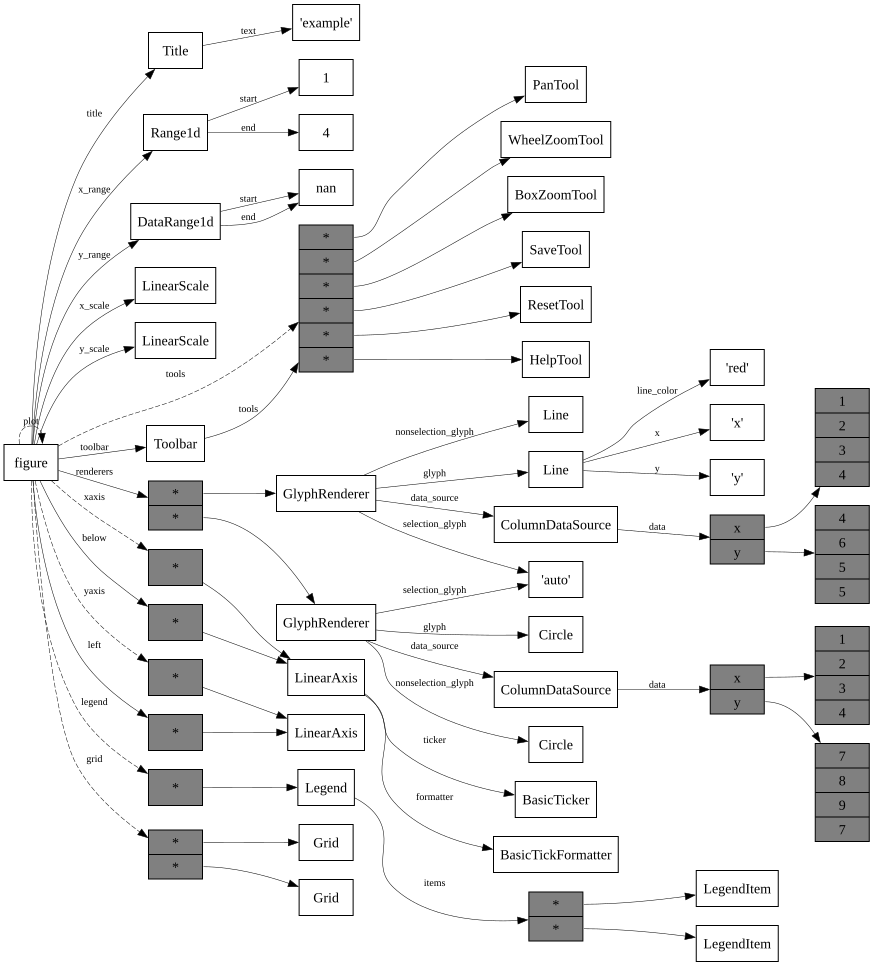

In [11]:
fig = figure(width=500, height=300, title="example", x_range=(1, 4))
line = fig.line([1, 2, 3, 4], [4, 6, 5, 5], color="red", legend_label="line1")
circle = fig.circle(
    [1, 2, 3, 4], [7, 8, 9, 7], 0.05, color="green", legend_label="line2"
)

from helper.dot import GraphvizBokeh
import graphviz

graph = GraphvizBokeh.graphviz(fig)
graphviz.Source(graph)

为了便于看清 `Model` 的属性，下面的代码把 `figure` 变成 JSON，再按树形显示。

In [12]:
import json

from IPython.display import display_json

show(fig)

# to_json() 返回字符串或 Serialized，要把内容整成能变成 JSON 的形状。
data = fig.document.to_json()
if hasattr(data, "content"):  # Bokeh 3.9 有时会返回 Serialized
    data = data.content
if isinstance(data, str):
    data = json.loads(data)


def plain(obj):
    # Buffer 这类不能变成 JSON 的值，只留类型名。
    if isinstance(obj, dict):
        return {k: plain(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [plain(v) for v in obj]
    if isinstance(obj, (str, int, float, bool)) or obj is None:
        return obj
    return f"<{type(obj).__name__}>"


display_json(plain(data)["roots"][0], raw=True)

### Bokeh 属性

Bokeh 属性带着类型与值的检查，`HasProps` 的派生类都有 Bokeh 属性，也备好了查看的方法：用 `properties()` 取得属性名的列表，用 `properties_with_values()` 取得名字与值的字典。

In [13]:
%col 4 fig.properties()

{'above',                       'align',                       'aspect_ratio',                'aspect_scale',               
 'attribution',                 'background_fill_alpha',       'background_fill_color',       'background_hatch_alpha',     
 'background_hatch_color',      'background_hatch_extra',      'background_hatch_pattern',    'background_hatch_scale',     
 'background_hatch_weight',     'below',                       'border_fill_alpha',           'border_fill_color',          
 'border_hatch_alpha',          'border_hatch_color',          'border_hatch_extra',          'border_hatch_pattern',       
 'border_hatch_scale',          'border_hatch_weight',         'border_line_alpha',           'border_line_cap',            
 'border_line_color',           'border_line_dash',            'border_line_dash_offset',     'border_line_join',           
 'border_line_width',           'center',                      'context_menu',                'css_classes',                


`properties_with_refs()` 返回持有别的模型的属性。

In [14]:
fig.properties_with_refs()

{'tags': List(AnyRef),
 'js_event_callbacks': Dict(String, List(Instance(Callback))),
 'js_property_callbacks': Dict(String, List(Instance(Callback))),
 'css_variables': Dict(String, Either(String, Instance(Node))),
 'styles': Either(Dict(String, Nullable(String)), Instance(Styles)),
 'stylesheets': List(Either(Instance(StyleSheet), String, Dict(String, Either(Dict(String, Nullable(String)), Instance(Styles))))),
 'context_menu': Nullable(Either(Instance(Menu), Enum('auto'))),
 'elements': List(Either(Instance(UIElement), Instance(DOMNode))),
 'x_range': Instance(Range),
 'y_range': Instance(Range),
 'x_scale': Instance(Scale),
 'y_scale': Instance(Scale),
 'extra_x_ranges': Dict(String, Instance(Range)),
 'extra_y_ranges': Dict(String, Instance(Range)),
 'extra_x_scales': Dict(String, Instance(Scale)),
 'extra_y_scales': Dict(String, Instance(Scale)),
 'title': Either(Null, Instance(Title)),
 'renderers': List(Instance(Renderer)),
 'toolbar': Instance(Toolbar),
 'left': List(Either(In

`dataspecs()` 返回能连到数据源的属性，下面是 `Circle` 的例子。

In [15]:
circle.glyph.dataspecs()

{'x': NumberSpec(String, Float, Instance(Value), Instance(Field), Instance(Expr), Struct(value=Float, transform=Instance(Transform)), Struct(field=String, transform=Instance(Transform)), Struct(expr=Instance(Expression), transform=Instance(Transform))),
 'y': NumberSpec(String, Float, Instance(Value), Instance(Field), Instance(Expr), Struct(value=Float, transform=Instance(Transform)), Struct(field=String, transform=Instance(Transform)), Struct(expr=Instance(Expression), transform=Instance(Transform))),
 'radius': DistanceSpec(units_default='data'),
 'line_color': ColorSpec(String, Nullable(Color), Instance(Value), Instance(Field), Instance(Expr), Struct(value=Nullable(Color), transform=Instance(Transform)), Struct(field=String, transform=Instance(Transform)), Struct(expr=Instance(Expression), transform=Instance(Transform))),
 'line_alpha': AlphaSpec(String, Float, Instance(Value), Instance(Field), Instance(Expr), Struct(value=Float, transform=Instance(Transform)), Struct(field=String, 

`lookup()` 按属性名取到属性的描述符：下面例子的 `toolbar_location` 是枚举型 `Enum`，可以看出只能从 `'above'`、`'below'`、`'left'`、`'right'` 这 4 个里选。

In [16]:
prop_desc = fig.lookup("toolbar_location")
print(prop_desc.property)

Nullable(Enum('above', 'below', 'left', 'right'))


`update()` 用关键字参数一次决定多个属性，下面改的是 x 轴显示范围的起点与终点。

In [17]:
fig.x_range.update(start=1, end=5)

`to_json()` 把对象变成 JSON 的结构。

### 查找模型

图是由很多模型组成的树，要找到想要的那个模型，就得顺着属性往下找。`Model` 有 `references()`、`select()`、`select_one()`，可以一次找完：`select()` 返回符合条件的对象的列表，`select_one()` 返回其中 1 个，符合的有 2 个以上时 `select_one()` 会抛异常。

条件写成字典，下面的程序找 `line_width` 为 `1` 的模型。

In [18]:
fig.references()

{AllIndices(id='p1258', ...),
 AllIndices(id='p1269', ...),
 AllLabels(id='p1230', ...),
 AllLabels(id='p1235', ...),
 AreaVisuals(id='p1245', ...),
 BasicTickFormatter(id='p1229', ...),
 BasicTickFormatter(id='p1234', ...),
 BasicTicker(id='p1228', ...),
 BasicTicker(id='p1233', ...),
 BoxAnnotation(id='p1240', ...),
 BoxInteractionHandles(id='p1246', ...),
 BoxZoomTool(id='p1239', ...),
 CDSView(id='p1257', ...),
 CDSView(id='p1268', ...),
 Circle(id='p1264', ...),
 Circle(id='p1265', ...),
 Circle(id='p1266', ...),
 ColumnDataSource(id='p1250', ...),
 ColumnDataSource(id='p1261', ...),
 DataRange1d(id='p1216', ...),
 GlyphRenderer(id='p1256', ...),
 GlyphRenderer(id='p1267', ...),
 Grid(id='p1231', ...),
 Grid(id='p1236', ...),
 HelpTool(id='p1249', ...),
 Legend(id='p1259', ...),
 LegendItem(id='p1260', ...),
 LegendItem(id='p1270', ...),
 Line(id='p1253', ...),
 Line(id='p1254', ...),
 Line(id='p1255', ...),
 LinearAxis(id='p1227', ...),
 LinearAxis(id='p1232', ...),
 LinearScale(

In [19]:
fig.select(dict(line_width=1))

[Circle(id='p1265', ...),
 Line(id='p1255', ...),
 Circle(id='p1266', ...),
 Line(id='p1254', ...),
 AreaVisuals(id='p1245', ...),
 Circle(id='p1264', ...),
 Line(id='p1253', ...)]

用 `type` 可以指定类型，下面用 `select()` 找到 `Grid`，把 `grid_line_dash` 改成点线。

In [20]:
from bokeh.models import Grid

for grid in fig.select(dict(type=Grid)):
    grid.grid_line_dash = "dotted"

`bokeh.core.query` 里有 `IN`、`OR`、`GT`、`LT` 等运算符，下面用 `IN` 选出 `Circle` 或 `Line`。

In [21]:
from bokeh.core.query import IN, OR
from bokeh.models import Circle, Line

fig.select(dict(type={IN: [Circle, Line]}))

[Circle(id='p1265', ...),
 Line(id='p1255', ...),
 Circle(id='p1266', ...),
 Line(id='p1254', ...),
 Circle(id='p1264', ...),
 Line(id='p1253', ...)]

In [22]:
fig.select({OR: [{"type": Circle}, {"type": Line}]})

[Circle(id='p1265', ...),
 Line(id='p1255', ...),
 Circle(id='p1266', ...),
 Line(id='p1254', ...),
 Circle(id='p1264', ...),
 Line(id='p1253', ...)]

关键字越多，返回的是全部符合条件的对象，下面是 `line_color` 为红的 `Line`。

In [23]:
fig.select(dict(type=Line, line_color="red"))

[Line(id='p1255', ...), Line(id='p1254', ...), Line(id='p1253', ...)]

`select()` 只返回符合条件的对象，不告诉它们在树里的哪个位置；用本书的 `find_path(root, target)` 就能得到从 `root` 到 `target` 的路径。

In [24]:
from helper.bokeh import find_path

for model in fig.select(dict(type={IN: [Circle, Line]})):
    model_path = find_path(fig, model, root_name="fig")
    print(f"{model_path} : {model}")

fig.renderers[1].nonselection_glyph : Circle(id='p1265', ...)


fig.renderers[0].muted_glyph : Line(id='p1255', ...)
fig.renderers[1].muted_glyph : Circle(id='p1266', ...)
fig.renderers[0].nonselection_glyph : Line(id='p1254', ...)


fig.renderers[1].glyph : Circle(id='p1264', ...)
fig.renderers[0].glyph : Line(id='p1253', ...)


把 `find_path()` 的 `all=True` 设上，就返回所有路径：折线有两条路径，第 2 条经过图例。

In [25]:
for p in find_path(fig, line, root_name="fig", all=True):
    print(p)

print()
print(fig.center[2])

fig.renderers[0]
fig.center[2].items[0].renderers[0]

Legend(id='p1259', ...)


`set_select()` 把查出来的对象的属性一次改掉：第 1 个参数是条件、第 2 个是属性与值，下面的程序把所有 `Line` 改成蓝色。

In [26]:
fig.set_select(dict(type=Line), dict(line_color="blue"))

`figure` 里搜索用得很多，为此关键字可以直接传给 `select()`。

In [27]:
fig.select(type={IN: [Circle, Line]})

[Circle(id='p1265', ...),
 Line(id='p1255', ...),
 Circle(id='p1266', ...),
 Line(id='p1254', ...),
 Circle(id='p1264', ...),
 Line(id='p1253', ...)]

In [28]:
fig.select(line_color="blue")

[Line(id='p1255', ...), Line(id='p1254', ...), Line(id='p1253', ...)]

### 回调函数

用 `on_change()` 能登记属性变化时调用的函数，函数会收到属性名、原来的值与新值，用 `remove_on_change()` 可以撤销登记。下面的例子在 `line.visible` 从 `True` 变成 `False` 时调用 `on_visible_changed()`。

这个函数只在用 Bokeh 服务器显示时才起作用。

In [29]:
def on_visible_changed(name, old, new):
    print(name, old, new)


line.visible = True
line.on_change("visible", on_visible_changed)
line.visible = False
line.remove_on_change("visible", on_visible_changed)

visible True False


图的绘制由浏览器的 JavaScript 做，Python 模型对应的对象在 JavaScript 那边也存在，用 `js_on_change()` 就能登记 JavaScript 的处理：第 1 个参数是事件名、第 2 个是 `CustomJS`，事件名写 `change:属性名` 或直接用属性名。处理里 `cb_obj` 是引起事件的模型，用 `args` 还能把别的模型传进去。

下面的例子在 `fig.x_range` 的 `start` 变化时调用 `callback`；`console.log()` 的结果请在浏览器开发者工具里查看。

In [30]:
from bokeh.models import CustomJS

fig = figure(width=500, height=300, title="example", x_range=(1, 3))
line = fig.line([1, 2, 3], [4, 6, 5], color="red", legend_label="line1")

callback = CustomJS(
    args=dict(line=line),
    code="""
console.log(line, cb_obj);
""",
)

fig.x_range.js_on_change("start", callback)
show(fig)

### 部件

`bokeh.models.widgets` 里备齐了界面的部件，多数用 `title` 放说明、用 `value` 放值：只显示文字的用 `label`，有多个名字的(`CheckBoxGroup`、`RadioGroup`)用 `labels`，能选值的(`Select`、`MultiSelect`)用 `options`。有值的部件用 `js_on_change()` 与 `on_change()` 响应，按钮则用 `js_on_click()` 与 `on_click()`。

下面把各种部件排起来显示。

In [31]:
from helper.bokeh import widgets_demo

widgets_demo()

### 布局

`bokeh.layouts` 里有 `Row`、`Column`、`GridBox`，把部件按横向、纵向、格子排列；用 `row()`、`column()`、`grid()` 这几个函数就能做出来：`row()` 与 `column()` 把要排的对象用列表或参数传进去，`grid()` 则用嵌套的列表，或者用一维的列表加 `ncols` 来决定列数。

下面的例子里，`row()` 排 4 个、`grid()` 把 10 个排成 5 列，再用 `column()` 把这两个纵向叠起来。

In [32]:
from bokeh.layouts import row, column, grid, Row, Column, GridBox
from bokeh.palettes import Category10_10
from bokeh.models import Div

layout = column(
    row([Div(width=65, height=50, background="lightgray") for i in range(4)]),
    grid(
        [Div(width=50, height=50, background=color) for color in Category10_10], ncols=5
    ),
)
show(layout)

## 小结

* Bokeh 在浏览器里画图，Python 只做数据与结构。
* Notebook 用 `output_notebook()`，HTML 用 `save()`，应用用 Bokeh 服务器。
* 更新有 3 种：JavaScript(写 `CustomJS`)、Python(需要 Bokeh 服务器)、用 `jupyter_bokeh` 试。
* 所有的类都在 `Model` → `HasProps` 之下，用 Bokeh 属性带着类型与默认值。
* 模型用 `select()`、`select_one()`、`references()` 找，路径用 `find_path()`。
* 属性的变化用 `on_change()`(Python)与 `js_on_change()`(JavaScript)来接。
* 部件在 `bokeh.models.widgets` 里，排布用 `row()`、`column()`、`grid()`。